In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import random

random.seed(42)

# part e

In [ ]:
test = (3 * (1 - mu)) / (4 * rho) + 1

In [2]:
def tokamak(t, state, mu, rho):
  x, y = state

  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y
  y_dot = rho * (x - 1) * y

  return [x_dot, y_dot]

In [18]:
t_max = 5000
t = np.linspace(0, t_max, 100000)

ic = [1+0.01, 1-mu + 0.01]

## plot without $g(x)$

### $c > \frac{1}{\mu} + \frac{\rho(1-\mu)}{\mu^{3/2}}$

$\rho = 50$

/tmp/ipykernel_36877/3932741559.py:4: RuntimeWarning: invalid value encountered in sqrt
  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y


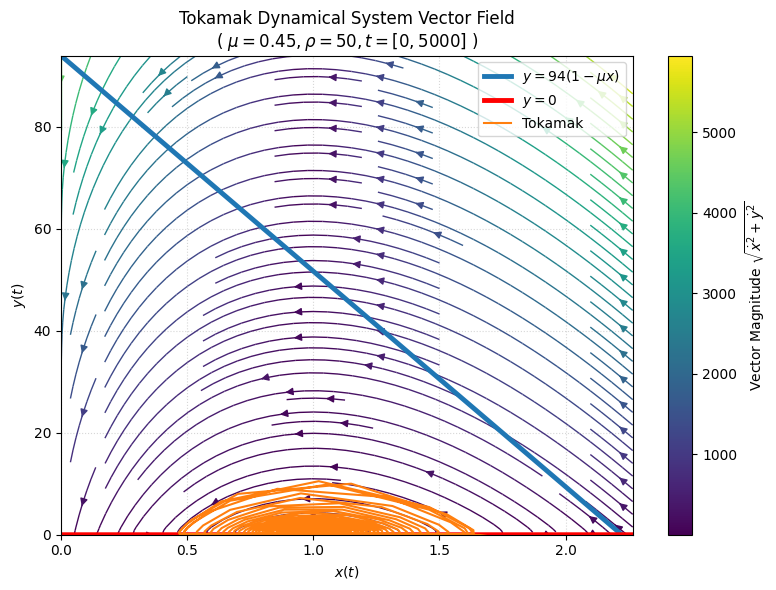

In [47]:
#########################
#### Tokamak System  ####
#########################

# tokamak parameters
mu = 0.45
rho = 50

# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t)

# x(t) and y(t)
x, y = solution.y


#########################
#### Trapping Region ####
#########################

# trapping region paramaters
little_c = 94

# points to plot trapping region
xs = np.linspace(0, xlim, 10000)

#########################
###### Stream Plot ######
#########################

# axis limits for plotting
xlim = np.mean(x) + 5 * np.std(x)  + 0.25 # "zooms in" on attractor
ylim = little_c

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")


#########################
##### Plot Results ######
#########################

ax.plot(xs, y1(xs, c = little_c),
        label = f"$y = {little_c}(1 - \\mu x)$",
        lw = 3.5)

ax.plot(xs, np.zeros_like(xs),
        label = r"$y=0$",
        lw = 3.5,
        color = 'red')

ax.plot(x, y,
        label = 'Tokamak')


#########################
#### Plot Parameters ####
#########################

ax.set_title(f"Tokamak Dynamical System Vector Field\n( $\\mu={mu}, \\rho={rho}, t = [0, {t_max}]$ )")
ax.set_xlabel("$x(t)$")
ax.set_ylabel("$y(t)$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(loc="upper right")

ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


### $c > 2 + \rho\sqrt{2}$

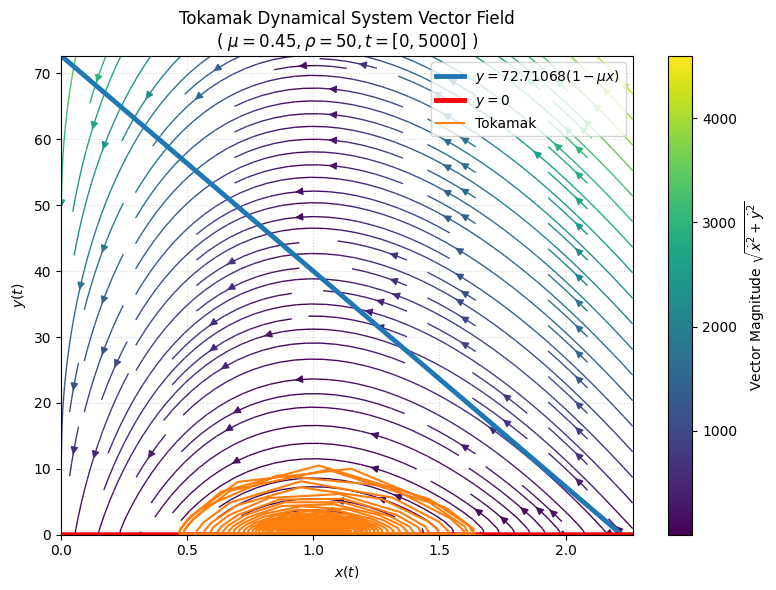

In [48]:
#########################
#### Trapping Region ####
#########################

# trapping region paramaters
little_c = np.round(2 + rho * np.sqrt(2), 5)

# points to plot trapping region
xs = np.linspace(0, xlim, 10000)

#########################
###### Stream Plot ######
#########################

# axis limits for plotting
xlim = np.mean(x) + 5 * np.std(x)  + 0.25 # "zooms in" on attractor
ylim = little_c

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")


#########################
##### Plot Results ######
#########################

ax.plot(xs, y1(xs, c = little_c),
        label = f"$y = {little_c}(1 - \\mu x)$",
        lw = 3.5)

ax.plot(xs, np.zeros_like(xs),
        label = r"$y=0$",
        lw = 3.5,
        color = 'red')

ax.plot(x, y,
        label = 'Tokamak')


#########################
#### Plot Parameters ####
#########################

ax.set_title(f"Tokamak Dynamical System Vector Field\n( $\\mu={mu}, \\rho={rho}, t = [0, {t_max}]$ )")
ax.set_xlabel("$x(t)$")
ax.set_ylabel("$y(t)$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(loc="upper right")

ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


### $c = \rho$

$\rho = 50$

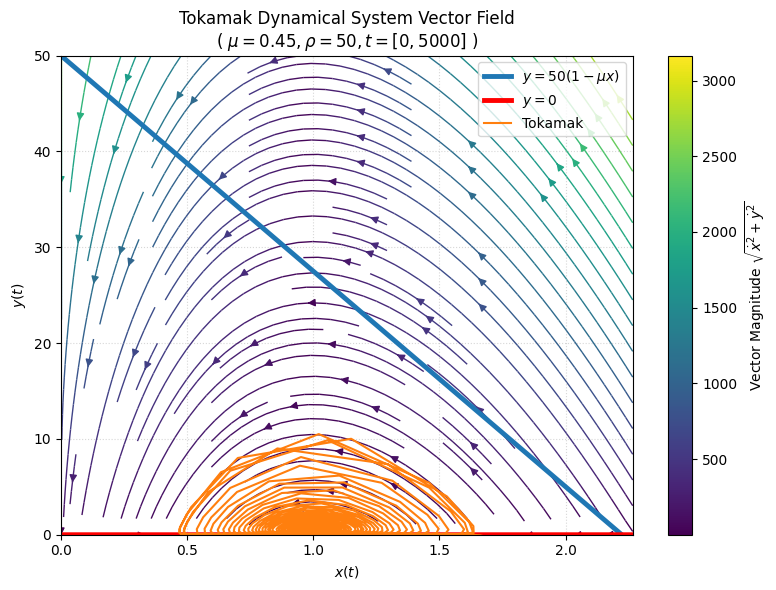

In [49]:
#########################
#### Trapping Region ####
#########################

# trapping region paramaters
little_c = rho

# points to plot trapping region
xs = np.linspace(0, xlim, 10000)

#########################
###### Stream Plot ######
#########################

# axis limits for plotting
xlim = np.mean(x) + 5 * np.std(x)  + 0.25 # "zooms in" on attractor
ylim = little_c

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")


#########################
##### Plot Results ######
#########################

ax.plot(xs, y1(xs, c = little_c),
        label = f"$y = {little_c}(1 - \\mu x)$",
        lw = 3.5)

ax.plot(xs, np.zeros_like(xs),
        label = r"$y=0$",
        lw = 3.5,
        color = 'red')

ax.plot(x, y,
        label = 'Tokamak')


#########################
#### Plot Parameters ####
#########################

ax.set_title(f"Tokamak Dynamical System Vector Field\n( $\\mu={mu}, \\rho={rho}, t = [0, {t_max}]$ )")
ax.set_xlabel("$x(t)$")
ax.set_ylabel("$y(t)$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(loc="upper right")

ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


### $c = \rho$

$\rho = 900$

/tmp/ipykernel_36877/3932741559.py:4: RuntimeWarning: invalid value encountered in sqrt
  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y


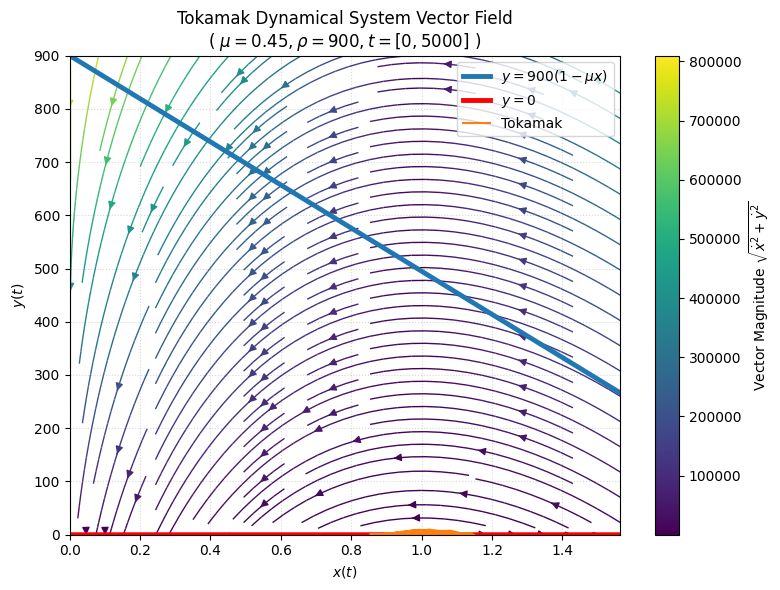

In [50]:
#########################
#### Tokamak System  ####
#########################

# tokamak parameters
mu = 0.45
rho = 900

# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t)

# x(t) and y(t)
x, y = solution.y


#########################
#### Trapping Region ####
#########################

# trapping region paramaters
little_c = np.round(rho, 5)

# points to plot trapping region
xs = np.linspace(0, xlim, 10000)


#########################
###### Stream Plot ######
#########################

# axis limits for plotting
xlim = np.mean(x) + 5 * np.std(x)  + 0.25 # "zooms in" on attractor
ylim = little_c

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")


#########################
##### Plot Results ######
#########################

ax.plot(xs, y1(xs, c = little_c),
        label = f"$y = {little_c}(1 - \\mu x)$",
        lw = 3.5)

ax.plot(xs, np.zeros_like(xs),
        label = r"$y=0$",
        lw = 3.5,
        color = 'red')

ax.plot(x, y,
        label = 'Tokamak')


#########################
#### Plot Parameters ####
#########################

ax.set_title(f"Tokamak Dynamical System Vector Field\n( $\\mu={mu}, \\rho={rho}, t = [0, {t_max}]$ )")
ax.set_xlabel("$x(t)$")
ax.set_ylabel("$y(t)$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(loc="upper right")

ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


## plot with $g(x)$

### $C = -20$

/tmp/ipykernel_36877/3932741559.py:4: RuntimeWarning: invalid value encountered in sqrt
  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y


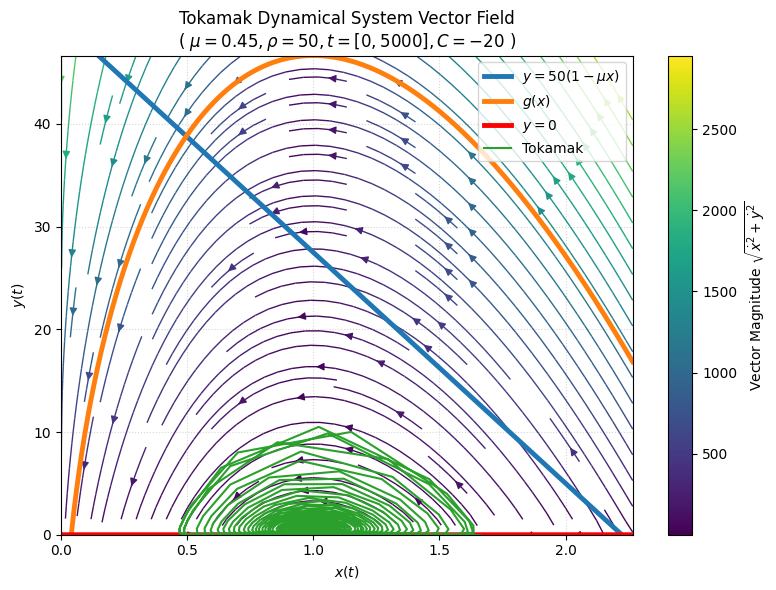

In [57]:
#########################
#### Tokamak System  ####
#########################

# tokamak parameters
mu = 0.45
rho = 50

# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t)

# x(t) and y(t)
x, y = solution.y


#########################
#### Trapping Region ####
#########################

# trapping region paramaters
little_c = rho

big_c = -20

# points to plot trapping region
xs = np.linspace(0, xlim, 10000)

def g(x, r, C): #g(x)
  return (- 2 * r * (x)**(3/2) / 3) + (2 * r * (x)**(1/2)) + C # need c here, too

#########################
###### Stream Plot ######
#########################

# axis limits for plotting
xlim = np.mean(x) + 5 * np.std(x)  + 0.25 # "zooms in" on attractor
ylim = max(g(xs, rho, big_c))

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")


#########################
##### Plot Results ######
#########################

ax.plot(xs, y1(xs, c = little_c),
        label = f"$y = {little_c}(1 - \\mu x)$",
        lw = 3.5)

ax.plot(xs, g(xs, r = rho, C = big_c),
        label = r"$g(x)$",
        lw = 3.5)

ax.plot(xs, np.zeros_like(xs),
        label = r"$y=0$",
        lw = 3.5,
        color = 'red')

ax.plot(x, y,
        label = 'Tokamak')


#########################
#### Plot Parameters ####
#########################

ax.set_title(f"Tokamak Dynamical System Vector Field\n( $\\mu={mu}, \\rho={rho}, t = [0, {t_max}], C = {big_c}$ )")
ax.set_xlabel("$x(t)$")
ax.set_ylabel("$y(t)$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(loc="upper right")

ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


### $C = -35$

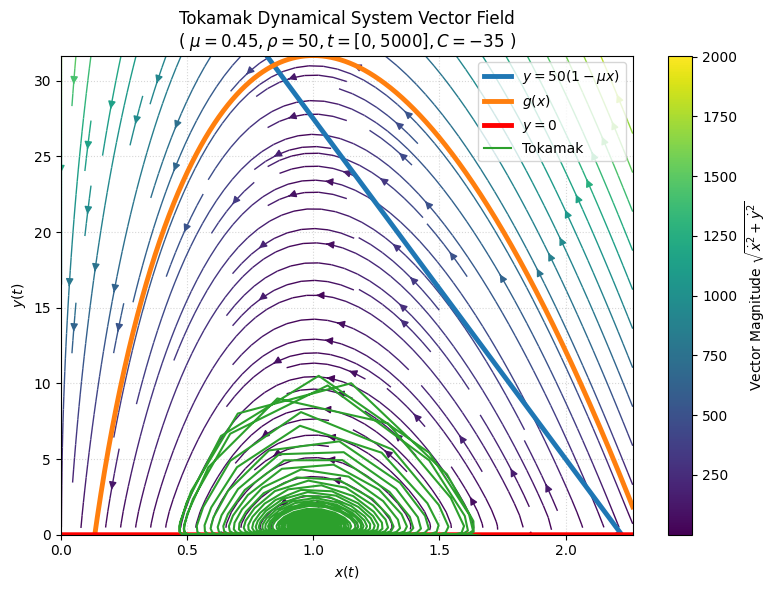

In [61]:
# #########################
# #### Tokamak System  ####
# #########################

# # tokamak parameters
# mu = 0.45
# rho = 50

# # solve system
# solution = solve_ivp(tokamak, [0, t_max], ic,
#                      args = (mu, rho),
#                      t_eval = t)

# # x(t) and y(t)
# x, y = solution.y


#########################
#### Trapping Region ####
#########################

# trapping region paramaters
little_c = rho

big_c = -35

# points to plot trapping region
xs = np.linspace(0, xlim, 10000)

def g(x, r, C): #g(x)
  return (- 2 * r * (x)**(3/2) / 3) + (2 * r * (x)**(1/2)) + C # need c here, too

#########################
###### Stream Plot ######
#########################

# axis limits for plotting
xlim = np.mean(x) + 5 * np.std(x)  + 0.25 # "zooms in" on attractor
ylim = max(g(xs, rho, big_c))

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")


#########################
##### Plot Results ######
#########################

ax.plot(xs, y1(xs, c = little_c),
        label = f"$y = {little_c}(1 - \\mu x)$",
        lw = 3.5)

ax.plot(xs, g(xs, r = rho, C = big_c),
        label = r"$g(x)$",
        lw = 3.5)

ax.plot(xs, np.zeros_like(xs),
        label = r"$y=0$",
        lw = 3.5,
        color = 'red')

ax.plot(x, y,
        label = 'Tokamak')


#########################
#### Plot Parameters ####
#########################

ax.set_title(f"Tokamak Dynamical System Vector Field\n( $\\mu={mu}, \\rho={rho}, t = [0, {t_max}], C = {big_c}$ )")
ax.set_xlabel("$x(t)$")
ax.set_ylabel("$y(t)$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(loc="upper right")

ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


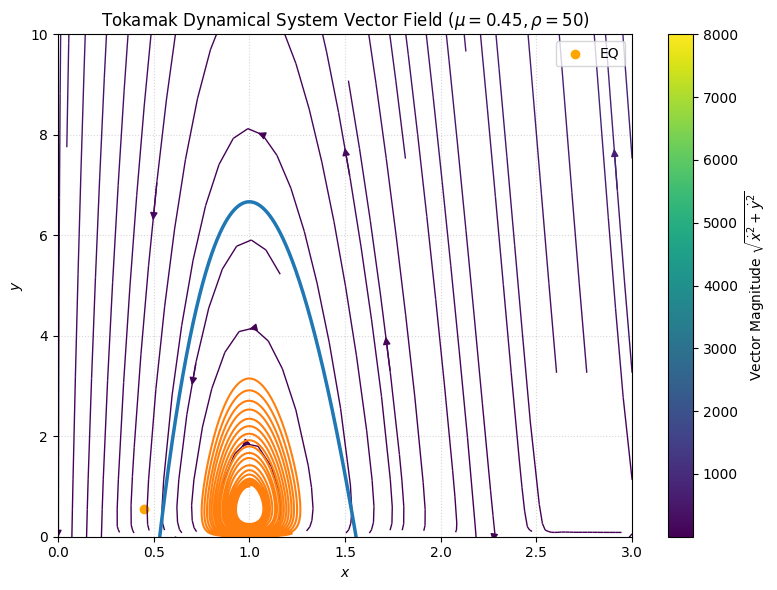

In [ ]:
mu = 0.45
rho = 50

xlim = 3
ylim = 80

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

# normalize arrow length
U_norm = np.where(speed > 0, U / speed, 0)
V_norm = np.where(speed > 0, V / speed, 0)



fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")

ax.scatter(mu, 1-mu, color = 'orange', marker = 'o', label = 'EQ')

# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t)

# x(t) and y(t)
x, y = solution.y

def y1(x, c):
  return c * (1 - (mu * x))

def y2(x, r, C): #g(x)
  return (- 2 * r * (x)**(3/2) / 3) + (2 * r * (x)**(1/2)) - C # need c here, too

xs = np.linspace(0, xlim, 6251)

ax.plot(xs, y2(xs, r = rho, C = 60),
        # label = f'y2, d = {d}, e = {e}',
        lw = 2.5)

ax.plot(x, y)


ax.set_title(f"Tokamak Dynamical System Vector Field ($\\mu={mu}, \\rho={rho}$)")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, 10)
ax.legend(loc="upper right")
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


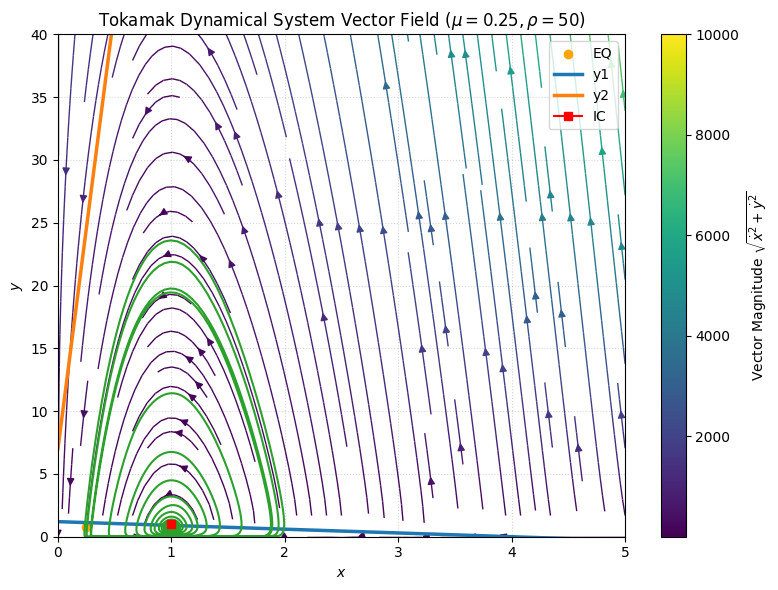

In [ ]:
mu = 0.25
rho = 50

xlim = 5
ylim = 50

# avoid NaNs from np.sqrt
x_vals = np.linspace(0.0, xlim, 250)
y_vals = np.linspace(-1, ylim, 250)
X, Y = np.meshgrid(x_vals, y_vals)

# vector field components
U, V = tokamak(0, [X, Y], mu, rho)
speed = np.hypot(U, V)

# normalize arrow length
U_norm = np.where(speed > 0, U / speed, 0)
V_norm = np.where(speed > 0, V / speed, 0)



fig, ax = plt.subplots(figsize=(8, 6))

# streamlines colored by vector magnitude
strm = ax.streamplot(X, Y, U, V,
    color=speed,
    cmap="viridis",
    density=1.3,
    linewidth=1.0,
    arrowsize=1.1,
)

# pretty colors
fig.colorbar(strm.lines, ax=ax,
             label="Vector Magnitude $\\sqrt{\\dot{x}^2 + \\dot{y}^2}$")

# # arrows
# step = 16
# ax.quiver(
#     X[::step, ::step],
#     Y[::step, ::step],
#     U_norm[::step, ::step],
#     V_norm[::step, ::step],
#     color="black",
#     alpha=0.45,
#     scale=28,
# )

ax.scatter(mu, 1-mu, color = 'orange', marker = 'o', label = 'EQ')

# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t)

# x(t) and y(t)
x, y = solution.y


def y1(x, c):
  return c * (1 - (mu * x))
def y2(x, d, e):
  return (d * (x+0.1)) - e

xs = np.linspace(0, xlim, 6251)

ax.plot(xs, y1(xs, c = 6/5),
        label = 'y1', lw = 2.5)

ax.plot(xs, y2(xs, d = 70, e = 0.01),
        label = 'y2', lw = 2.5)

ax.plot(x, y)

ax.plot(ic[0], ic[1], label = "IC",
         marker = 's', color = 'red')


ax.set_title(f"Tokamak Dynamical System Vector Field ($\\mu={mu}, \\rho={rho}$)")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_xlim(0, xlim)
ax.set_ylim(0, 40)
ax.legend(loc="upper right")
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


/tmp/ipykernel_5013/3932741559.py:4: RuntimeWarning: invalid value encountered in sqrt
  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y


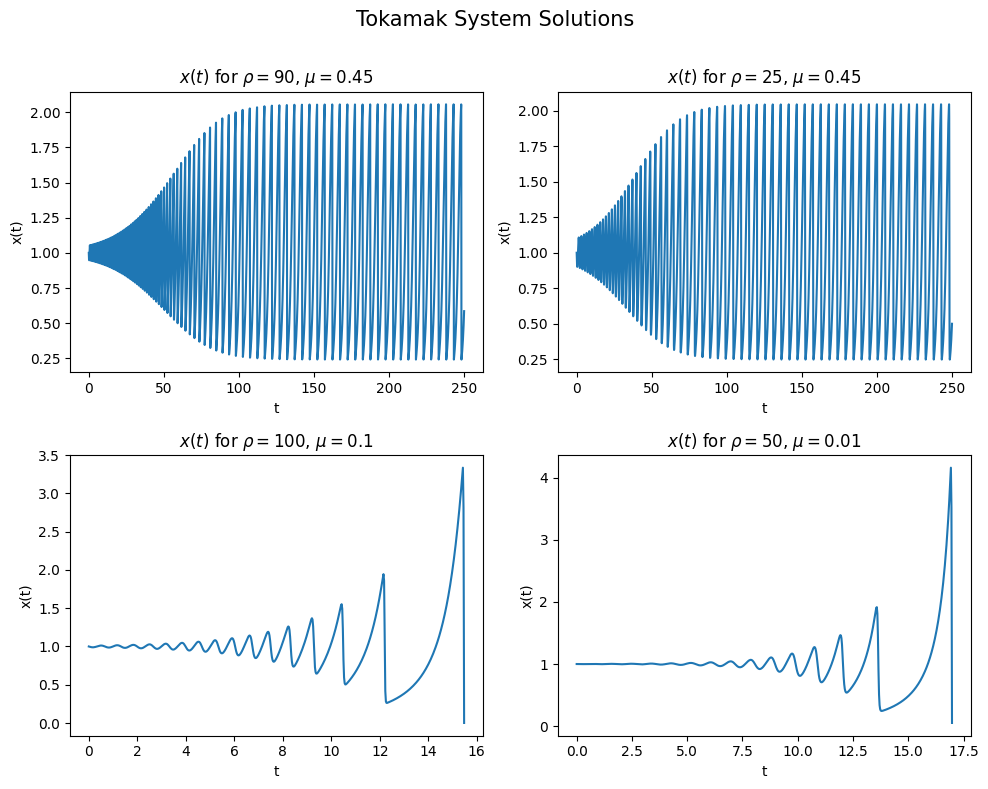

In [ ]:
t_max = 250
t = np.linspace(0, t_max, 10000)

rho_mu = [(90, 0.45), (25, 0.45), (100, 0.1), (50, 0.01)]

fig, axs = plt.subplots(2, 2, figsize = (10, 8))
axs = axs.flatten()

for i, (rho, mu) in enumerate(rho_mu):
  t = np.linspace(0, t_max, 10000)
  solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t,
                     max_step = 0.001)

  x, y = solution.y
  t =t[:len(x)]
  axs[i].plot(t, x)
  axs[i].set_xlabel("t")
  axs[i].set_ylabel("x(t)")
  # axs[i].set_xlim(0, 1000)
  axs[i].set_title(rf'$x(t)$ for $\rho = ${rho}, $\mu = ${mu}')

fig.suptitle("Tokamak System Solutions\n",
             fontsize = 15)
plt.tight_layout()
plt.show()

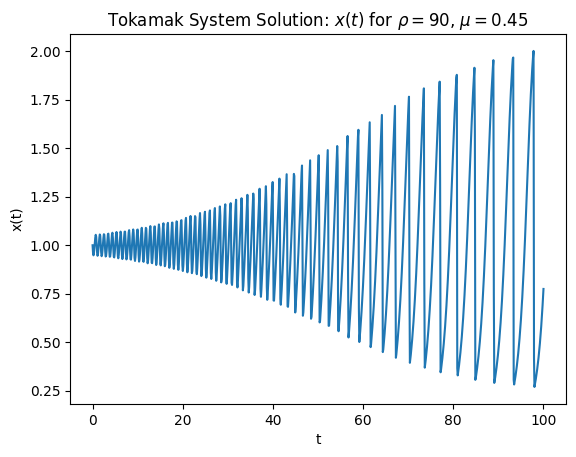

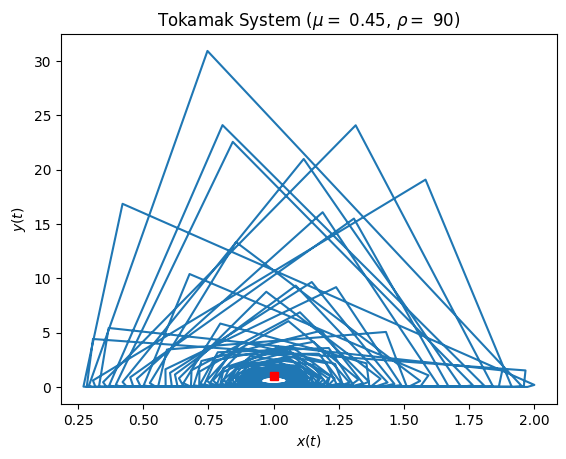

In [ ]:
t_max = 100
t = np.linspace(0, t_max, 1000)

ic = [1, 1]

# # parameters
rho = 90    # rho >> 1
mu = 0.45   # 0 < mu < 1

# solve system
solution = solve_ivp(tokamak, [0, t_max],
                     ic,
                     args = (mu, rho),
                     t_eval = t,
                     max_step = 0.001)

# x(t) and y(t)
x, y = solution.y

plt.plot(t, x)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(rf'Tokamak System Solution: $x(t)$ for $\rho = ${rho}, $\mu = ${mu}')
plt.show()

plt.plot(x, y)
plt.plot(ic[0], ic[1], label = "IC",
         marker = 's', color = 'red')

plt.xlabel(r"$x(t)$")
plt.ylabel(r"$y(t)$")
plt.title(rf"Tokamak System ($\mu = $ {mu}, $\rho = $ {rho})")
plt.show()

/tmp/ipykernel_5013/3932741559.py:4: RuntimeWarning: invalid value encountered in sqrt
  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y


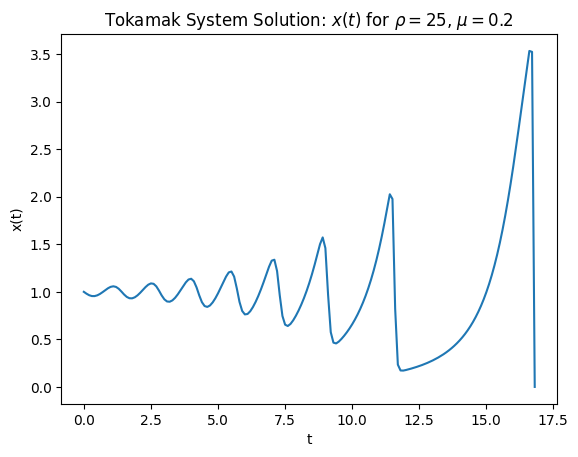

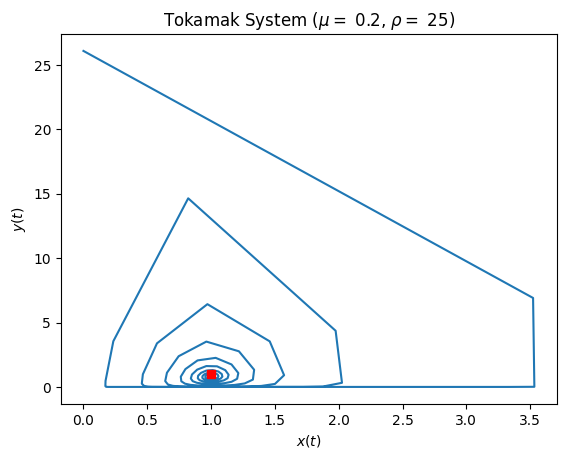

In [ ]:
# # parameters
rho = 25    # rho >> 1
mu = 0.2   # 0 < mu < 1


# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t,
                     max_step = 0.001)

# x(t) and y(t)
x, y = solution.y

t = t[:len(x)]
plt.plot(t, x)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(rf'Tokamak System Solution: $x(t)$ for $\rho = ${rho}, $\mu = ${mu}')
plt.show()

plt.plot(x, y)
plt.plot(ic[0], ic[1], label = "IC",
         marker = 's', color = 'red')

plt.xlabel(r"$x(t)$")
plt.ylabel(r"$y(t)$")
plt.title(rf"Tokamak System ($\mu = $ {mu}, $\rho = $ {rho})")
plt.show()

/tmp/ipykernel_5013/3932741559.py:4: RuntimeWarning: invalid value encountered in sqrt
  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y


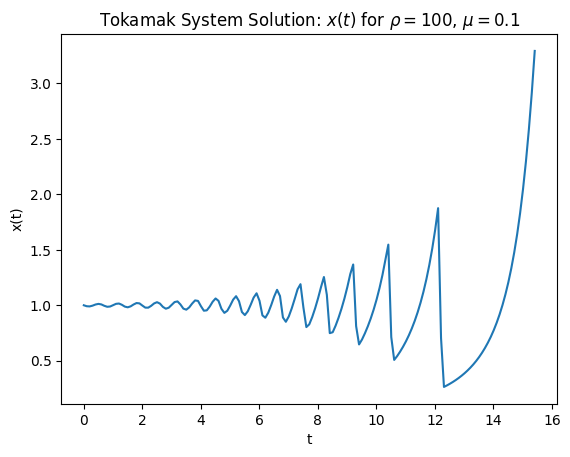

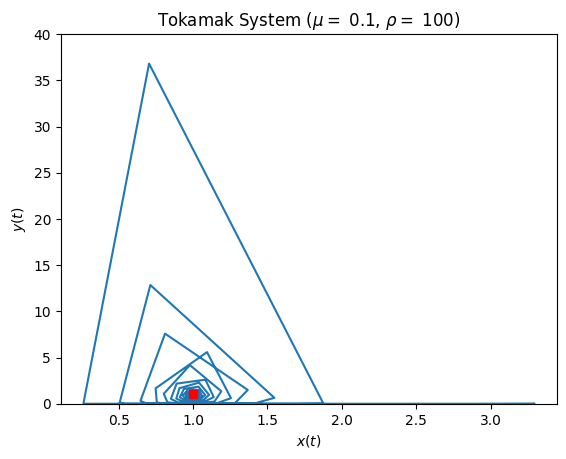

In [ ]:
# # parameters
rho = 100    # rho >> 1
mu = 0.1   # 0 < mu < 1

# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t,
                     max_step = 0.001)

# x(t) and y(t)
x, y = solution.y

t = t[:len(x)]
plt.plot(t, x)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(rf'Tokamak System Solution: $x(t)$ for $\rho = ${rho}, $\mu = ${mu}')
plt.show()


plt.plot(x, y)

plt.plot(ic[0], ic[1], label = "IC",
         marker = 's', color = 'red')

# plt.xlim(0,20)
plt.ylim(0,40)
plt.xlabel(r"$x(t)$")
plt.ylabel(r"$y(t)$")

plt.title(rf"Tokamak System ($\mu = $ {mu}, $\rho = $ {rho})")
plt.show()

/tmp/ipykernel_5013/3932741559.py:4: RuntimeWarning: invalid value encountered in sqrt
  x_dot = (1 - mu * x) * np.sqrt(x**3) - np.sqrt(x) * y


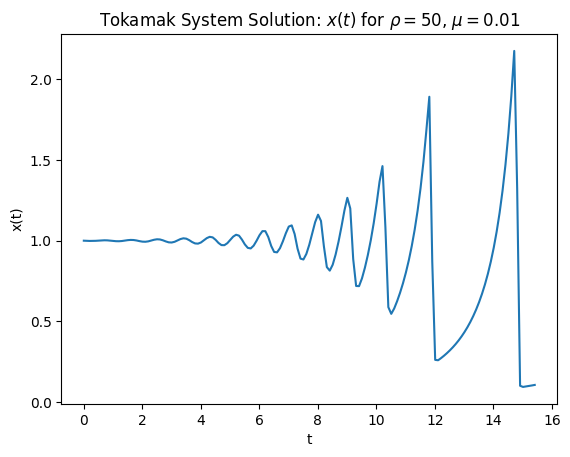

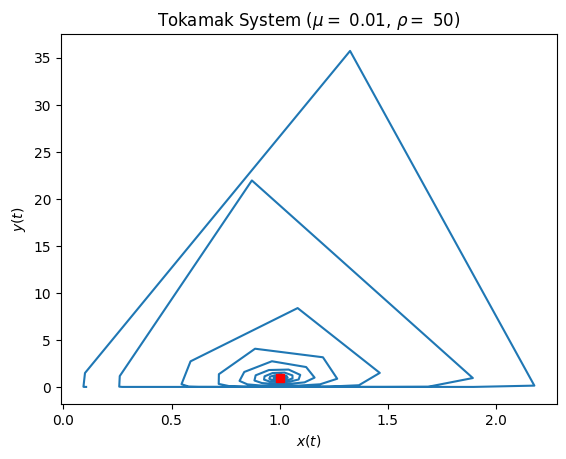

In [ ]:
# # parameters
rho = 50    # rho >> 1
mu = 0.01   # 0 < mu < 1

# solve system
solution = solve_ivp(tokamak, [0, t_max], ic,
                     args = (mu, rho),
                     t_eval = t)

# x(t) and y(t)
x, y = solution.y

t = t[:len(x)]
plt.plot(t, x)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(rf'Tokamak System Solution: $x(t)$ for $\rho = ${rho}, $\mu = ${mu}')
plt.show()

plt.plot(x, y)
plt.plot(ic[0], ic[1], label = "IC",
         marker = 's', color = 'red')

plt.xlabel(r"$x(t)$")
plt.ylabel(r"$y(t)$")
plt.title(rf"Tokamak System ($\mu = $ {mu}, $\rho = $ {rho})")
plt.show()

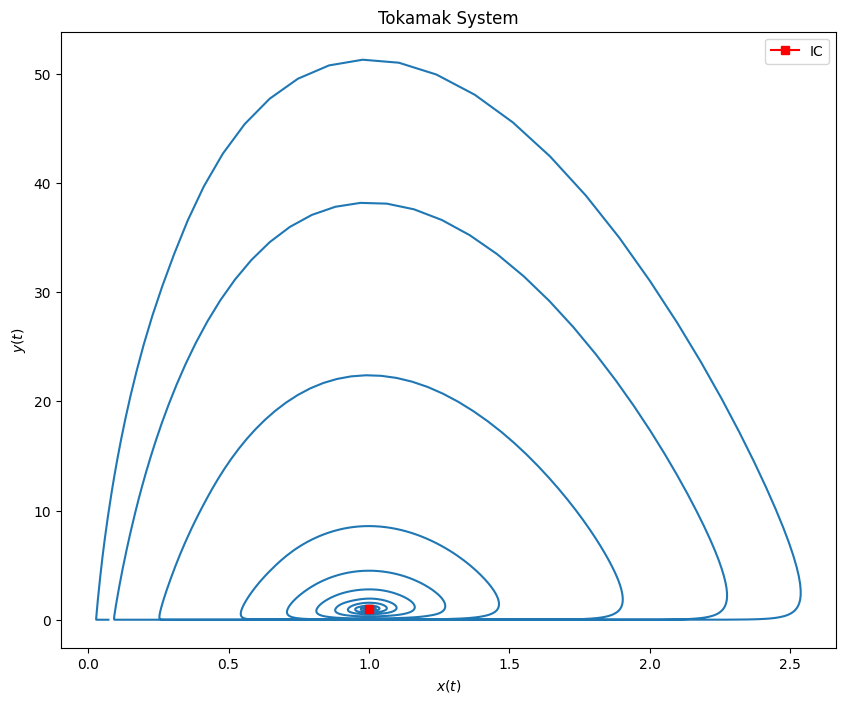

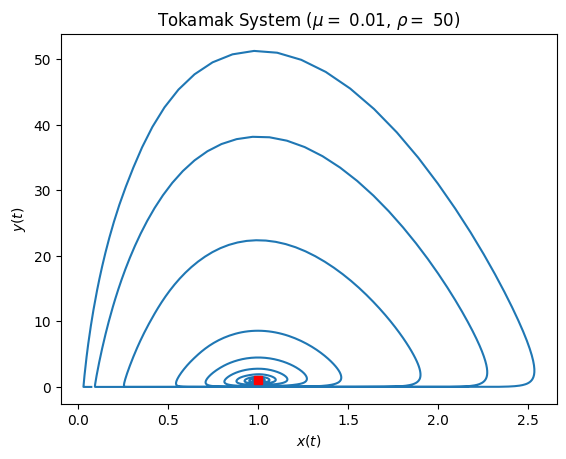

In [ ]:
# plot results
plt.figure(figsize = (10,8))

plt.plot(x, y)
plt.plot(ic[0], ic[1], label = "IC",
         marker = 's', color = 'red')

plt.xlabel(r"$x(t)$")
plt.ylabel(r"$y(t)$")
plt.title("Tokamak System")
plt.legend()

plt.show()

plt.plot(x, y)
plt.plot(ic[0], ic[1], label = "IC",
         marker = 's', color = 'red')

plt.xlabel(r"$x(t)$")
plt.ylabel(r"$y(t)$")
plt.title(rf"Tokamak System ($\mu = $ {mu}, $\rho = $ {rho})")
plt.show()